In [4]:
from joblib import Parallel, delayed
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from experimental import scan_gaps


def scan1(alpha_goal):
    energies = scan_gaps(3, alpha_goal, iters=150, gap_min=0.01, gap_max=100)
    _, _, e_values, _ = zip(*energies)
    min_gaps = energies[np.argmin(e_values)]
    return alpha_goal, *min_gaps


best_gaps = Parallel(n_jobs=-2)(
    delayed(scan1)(alpha) for alpha in tqdm(np.linspace(0.50001, 0.999, 200), leave=True)
)




  0%|          | 0/200 [00:00<?, ?it/s]


 15%|█▌        | 30/200 [00:04<00:28,  6.06it/s]


 22%|██▎       | 45/200 [00:10<00:39,  3.91it/s]


 30%|███       | 60/200 [00:16<00:42,  3.32it/s]


 38%|███▊      | 75/200 [00:22<00:42,  2.97it/s]


 45%|████▌     | 90/200 [00:28<00:38,  2.84it/s]


 52%|█████▎    | 105/200 [00:33<00:34,  2.77it/s]


 60%|██████    | 120/200 [00:39<00:29,  2.73it/s]


 68%|██████▊   | 135/200 [00:45<00:23,  2.71it/s]


 75%|███████▌  | 150/200 [00:50<00:18,  2.69it/s]


 82%|████████▎ | 165/200 [00:56<00:13,  2.68it/s]


 90%|█████████ | 180/200 [01:02<00:07,  2.67it/s]


100%|██████████| 200/200 [01:07<00:00,  2.95it/s]


  0%|          | 0/300 [03:55<?, ?it/s]


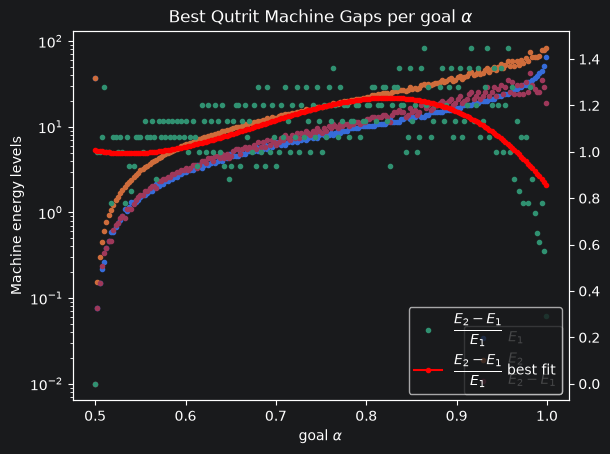

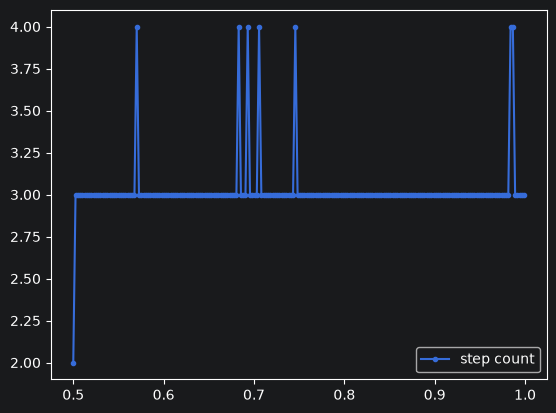

In [5]:
alphas, gap1s, gap2s, energies, step_count = zip(*best_gaps)
ax = plt.gca()
ax.set_yscale('log')
ax.scatter(alphas, gap1s, marker='.', label=r"$E_1$")
ax.scatter(alphas, np.array(gap2s) + np.array(gap1s), marker='.', label=r"$E_2$")
ax.scatter(alphas, gap2s, marker='.', label=r"$E_2 - E_1$")
ax2 = ax.twinx()
ax2._get_lines = ax._get_lines
ax2._get_patches_for_fill = ax._get_patches_for_fill
#ax2.plot(temps, np.array(gap2s) - np.array(gap1s), marker='.', label=r"$E_2 - 2E_1$")
gap_ratio = np.array(gap2s) / np.array(gap1s)
poly = np.polynomial.polynomial.Polynomial.fit(alphas, gap_ratio, 3)
#exponential = np.polynomial.polynomial.Polynomial.fit(alphas, np.log(gap_ratio), 7)
ax2.scatter(alphas, gap_ratio, marker='.', label=r"$\dfrac{E_2-E_1}{E_1}$")
ax2.plot(alphas, poly(alphas), marker='.', label=r"$\dfrac{E_2-E_1}{E_1}$ best fit", color='red')
#ax2.plot(temps, (np.array(gap2s) + np.array(gap1s)) / np.array(gap1s), marker='.', label=r"$\dfrac{E_2}{E_1}$")

ax.set_ylabel(r"Machine energy levels")
ax.set_xlabel(r"goal $\alpha$")
#ax2.set_ylabel(r"Energy level ratios/differences")
plt.title(r'Best Qutrit Machine Gaps per goal $\alpha$')
ax.legend()
ax2.legend(loc=4)
#ax.get_yaxis().set_visible(False)
#ax.set_ylim((0, ax.get_ylim()[1]))
#plt.grid(True)

plt.show()

ax = plt.gca()
ax.plot(alphas, step_count, marker='.', label=r"step count")
plt.legend()
plt.show()

In [7]:
from joblib import Parallel, delayed


def scan1(temp):
    energies = scan_gaps(3, alpha_goal=0.8, iters=200, temp=temp)
    _, _, e_values, _ = zip(*energies)
    min_gaps = energies[np.argmin(e_values)]
    return (temp, *min_gaps)


#best_gaps = [scan1(temp) for temp in tqdm(np.logspace(-1, 2, 100), leave=True)]
best_gaps = Parallel(n_jobs=-2)(
    delayed(scan1)(temp) for temp in tqdm(np.logspace(-1, 2, 100), leave=True)
)


100%|██████████| 100/100 [00:49<00:00,  2.03it/s][A


  0%|          | 0/100 [18:54<?, ?it/s]


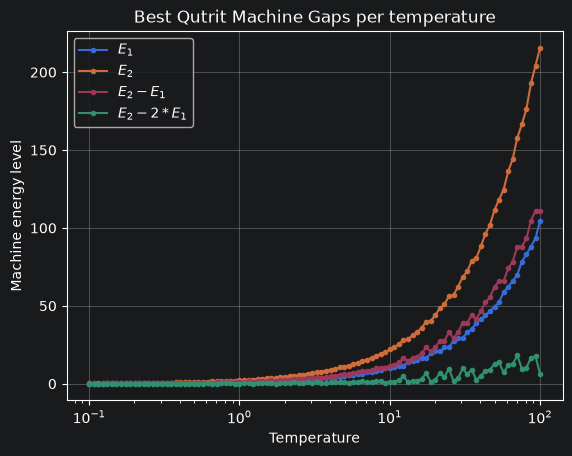

In [11]:
alphas, gap1s, gap2s, energies, _ = zip(*best_gaps)
plt.semilogx(alphas, gap1s, marker='.', label=r"$E_1$")
plt.semilogx(alphas, np.array(gap2s) + np.array(gap1s), marker='.', label=r"$E_2$")
plt.semilogx(alphas, gap2s, marker='.', label=r"$E_2 - E_1$")
plt.semilogx(alphas, np.array(gap2s) - np.array(gap1s), marker='.', label=r"$E_2 - 2*E_1$")
plt.ylabel(r"Machine energy level")
plt.xlabel(r"Temperature")
plt.title(rf'Best Qutrit Machine Gaps per temperature')
plt.legend()
ax = plt.gca()
#ax.set_ylim((0, ax.get_ylim()[1]))
plt.grid(True)
plt.show()